In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [2]:
df = pd.read_csv("../data/processed/weather_dataset_2024_2026.csv", parse_dates=["time"])

train = df[df["time"].dt.year == 2024]
val = df[df["time"].dt.year == 2025]
test = df[df["time"].dt.year == 2026]

print("Training:", train.shape)
print("Validation:", val.shape)
print("Testing:", test.shape)

Training: (2208, 13)
Validation: (2208, 13)
Testing: (2208, 13)


**TEMPERATUUR:**

In [3]:
features = [
    "temperature_ECMWF",
    "temperature_GFS",
    "temperature_ICON_EU"
]

target = "actual_temperature"

X_train = train[features]
y_train = train[target]

X_val = val[features]
y_val = val[target]

In [4]:
# Treenime
lr = LinearRegression()
lr.fit(X_train, y_train)

# Ennustame
lr_pred = lr.predict(X_val)

print("Linear Regression")
print("MAE:", mean_absolute_error(y_val, lr_pred))
print("RMSE:", root_mean_squared_error(y_val, lr_pred))

Linear Regression
MAE: 1.075505726869139
RMSE: 1.4023368291606384


In [5]:
comparison = pd.DataFrame({
    "Actual": y_val.values,
    "Predicted": lr_pred,
    "ICON-EU": val["temperature_ICON_EU"].values
})

display(comparison.head(10))

,Actual,Predicted,ICON-EU
0,10.4,8.785878,8.9
1,8.7,8.106132,8.2
2,7.7,7.356383,7.3
3,6.6,6.883920,6.7
4,5.8,6.635230,6.3
5,5.2,7.501194,7.3
6,6.5,8.995779,8.9
7,9.7,10.933132,10.9
8,12.1,12.494598,12.5
9,13.7,14.214218,14.4


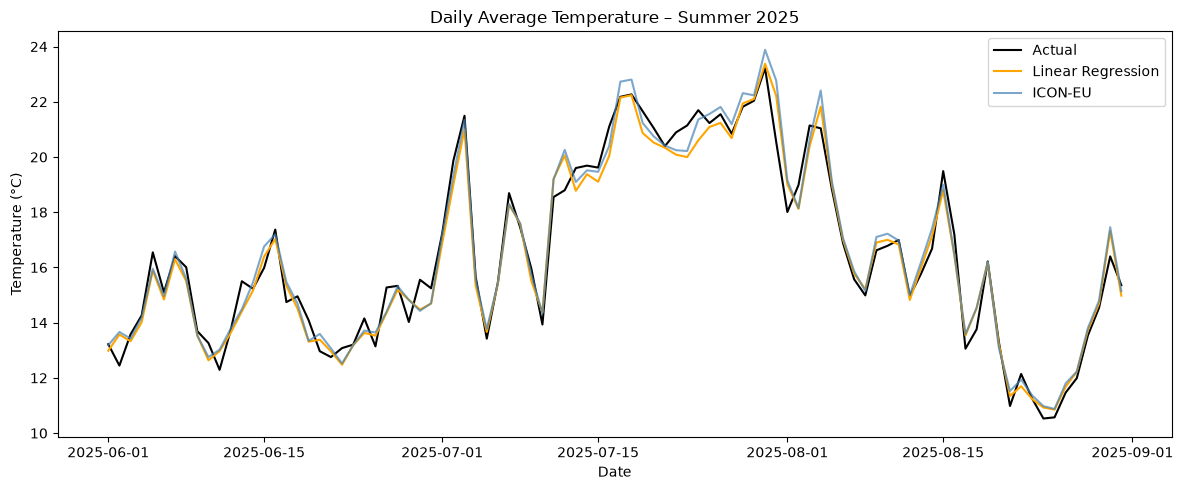

In [6]:
daily = pd.DataFrame({
    "time": val["time"].values,
    "Actual": y_val.values,
    "Linear Regression": lr_pred,
    "ICON-EU": val["temperature_ICON_EU"].values
})

daily = daily.set_index("time").resample("D").mean()

plt.figure(figsize=(12, 5))

plt.plot(daily.index, daily["Actual"], label="Actual", color="black")
plt.plot(daily.index, daily["Linear Regression"], label="Linear Regression", color="orange")
plt.plot(daily.index, daily["ICON-EU"], label="ICON-EU", color="steelblue", alpha=0.7)

plt.title("Daily Average Temperature – Summer 2025")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()

plt.tight_layout()
plt.show()

In [7]:
print("ICON-EU")
print("MAE:", mean_absolute_error(y_val, val["temperature_ICON_EU"]))
print("RMSE:", root_mean_squared_error(y_val, val["temperature_ICON_EU"]))

print("\nLinear Regression")
print("MAE:", mean_absolute_error(y_val, lr_pred))
print("RMSE:", root_mean_squared_error(y_val, lr_pred))

ICON-EU
MAE: 1.0879528985507245
RMSE: 1.4104103113551076

Linear Regression
MAE: 1.075505726869139
RMSE: 1.4023368291606384


In [8]:
for feature, coefficient in zip(features, lr.coef_):
    print(f"{feature}: {coefficient:.4f}")

print(f"Intercept: {lr.intercept_:.4f}")

temperature_ECMWF: 0.2657
temperature_GFS: -0.0806
temperature_ICON_EU: 0.8009
Intercept: 0.0344


In [9]:
rf = RandomForestRegressor(
    n_estimators=250,
    random_state=42,
    max_depth=5,
    min_samples_leaf=10,
    max_features=1.0
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_val)

print("Random Forest")
print("MAE:", mean_absolute_error(y_val, rf_pred))
print("RMSE:", root_mean_squared_error(y_val, rf_pred))

Random Forest
MAE: 1.123431176278016
RMSE: 1.454185916191418


**TUUL:**

In [10]:
wind_features = [
    "wind_speed_ECMWF",
    "wind_speed_GFS",
    "wind_speed_ICON_EU"
]

wind_target = "actual_wind_speed"

X_train_wind = train[wind_features]
y_train_wind = train[wind_target]

X_val_wind = val[wind_features]
y_val_wind = val[wind_target]

# Treenime mudeli
wind_lr = LinearRegression()
wind_lr.fit(X_train_wind, y_train_wind)

# Ennustame 2025. aasta tuule kiirust
wind_lr_pred = wind_lr.predict(X_val_wind)

print("Linear Regression – Wind Speed")
print("MAE:", mean_absolute_error(y_val_wind, wind_lr_pred))
print("RMSE:", root_mean_squared_error(y_val_wind, wind_lr_pred))

Linear Regression – Wind Speed
MAE: 0.6753339052859436
RMSE: 0.8680346638880978


In [11]:
print("ICON-EU")
print("MAE:", mean_absolute_error(y_val_wind, val["wind_speed_ICON_EU"]))
print("RMSE:", root_mean_squared_error(y_val_wind, val["wind_speed_ICON_EU"]))

print("\nLinear Regression")
print("MAE:", mean_absolute_error(y_val_wind, wind_lr_pred))
print("RMSE:", root_mean_squared_error(y_val_wind, wind_lr_pred))

ICON-EU
MAE: 0.7252581521739131
RMSE: 0.9415711362983389

Linear Regression
MAE: 0.6753339052859436
RMSE: 0.8680346638880978


In [12]:
for feature, coefficient in zip(wind_features, wind_lr.coef_):
    print(f"{feature}: {coefficient:.4f}")

print(f"Intercept: {wind_lr.intercept_:.4f}")

wind_speed_ECMWF: 0.1717
wind_speed_GFS: 0.1495
wind_speed_ICON_EU: 0.3871
Intercept: 0.2348


In [13]:
wind_rf = RandomForestRegressor(
    n_estimators=250,
    random_state=42,
    max_depth=5,
    min_samples_leaf=10,
    max_features=1.0
)

wind_rf.fit(X_train_wind, y_train_wind)

wind_rf_pred = wind_rf.predict(X_val_wind)

print("Random Forest – Wind Speed")
print("MAE:", mean_absolute_error(y_val_wind, wind_rf_pred))
print("RMSE:", root_mean_squared_error(y_val_wind, wind_rf_pred))

Random Forest – Wind Speed
MAE: 0.6838752418899281
RMSE: 0.8827817175044966


**SADEMED**

In [14]:
rain_features = [
    "precipitation_ECMWF",
    "precipitation_GFS",
    "precipitation_ICON_EU"
]

X_train_rain = train[rain_features]
X_val_rain = val[rain_features]

y_train_rain = (train["actual_precipitation"] > 0).astype(int)
y_val_rain = (val["actual_precipitation"] > 0).astype(int)

In [15]:
rain_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

rain_lr.fit(X_train_rain, y_train_rain)

rain_lr_prob = rain_lr.predict_proba(X_val_rain)[:, 1]
rain_lr_pred = (rain_lr_prob >= 0.55).astype(int)

print("Logistic Regression – Precipitation")
print("Accuracy:", accuracy_score(y_val_rain, rain_lr_pred))
print("Precision:", precision_score(y_val_rain, rain_lr_pred, zero_division=0))
print("Recall:", recall_score(y_val_rain, rain_lr_pred, zero_division=0))
print("F1-score:", f1_score(y_val_rain, rain_lr_pred, zero_division=0))

Logistic Regression – Precipitation
Accuracy: 0.8374094202898551
Precision: 0.38875878220140514
Recall: 0.6287878787878788
F1-score: 0.4804630969609262


In [16]:
icon_rain_pred = (
    val["precipitation_ICON_EU"] > 0
).astype(int)

rain_results = pd.DataFrame({
    "Model": ["ICON-EU", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_val_rain, icon_rain_pred),
        accuracy_score(y_val_rain, rain_lr_pred)
    ],
    "Precision": [
        precision_score(y_val_rain, icon_rain_pred, zero_division=0),
        precision_score(y_val_rain, rain_lr_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_val_rain, icon_rain_pred, zero_division=0),
        recall_score(y_val_rain, rain_lr_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_val_rain, icon_rain_pred, zero_division=0),
        f1_score(y_val_rain, rain_lr_pred, zero_division=0)
    ]
})

display(rain_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,ICON-EU,0.8066,0.3424,0.6705,0.4533
1,Logistic Regression,0.8374,0.3888,0.6288,0.4805


In [17]:
rain_prob = rain_lr.predict_proba(X_val_rain)[:, 1]

comparison = pd.DataFrame({
    "Actual": y_val_rain.values,
    "Rain Probability": rain_prob,
    "Predicted": rain_lr_pred
})

display(comparison.head(10).round(3))

,Actual,Rain Probability,Predicted
0,0,0.299,0
1,0,0.299,0
2,0,0.299,0
3,0,0.299,0
4,0,0.299,0
5,0,0.299,0
6,0,0.299,0
7,0,0.299,0
8,0,0.299,0
9,0,0.299,0


In [18]:
rain_rf = RandomForestClassifier(
    n_estimators=250,
    max_depth=5,
    min_samples_leaf=10,
    max_features=1.0,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rain_rf.fit(X_train_rain, y_train_rain)

rain_rf_prob = rain_rf.predict_proba(X_val_rain)[:, 1]
rain_rf_pred = (rain_rf_prob >= 0.70).astype(int)

print("Random Forest – Precipitation")
print("Accuracy:", accuracy_score(y_val_rain, rain_rf_pred))
print("Precision:", precision_score(y_val_rain, rain_rf_pred, zero_division=0))
print("Recall:", recall_score(y_val_rain, rain_rf_pred, zero_division=0))
print("F1-score:", f1_score(y_val_rain, rain_rf_pred, zero_division=0))

Random Forest – Precipitation
Accuracy: 0.8161231884057971
Precision: 0.3442982456140351
Recall: 0.5946969696969697
F1-score: 0.4361111111111111


In [19]:
rain_comparison = pd.DataFrame({
    "Model": ["ICON-EU", "Logistic Regression", "Random Forest"],
    "Precision": [
        precision_score(y_val_rain, icon_rain_pred),
        precision_score(y_val_rain, rain_lr_pred),
        precision_score(y_val_rain, rain_rf_pred)
    ],
    "Recall": [
        recall_score(y_val_rain, icon_rain_pred),
        recall_score(y_val_rain, rain_lr_pred),
        recall_score(y_val_rain, rain_rf_pred)
    ],
    "F1-score": [
        f1_score(y_val_rain, icon_rain_pred),
        f1_score(y_val_rain, rain_lr_pred),
        f1_score(y_val_rain, rain_rf_pred)
    ]
})

display(rain_comparison.round(4))

,Model,Precision,Recall,F1-score
0,ICON-EU,0.3424,0.6705,0.4533
1,Logistic Regression,0.3888,0.6288,0.4805
2,Random Forest,0.3443,0.5947,0.4361


**Final Model Evaluation – 2026**

In [20]:
train_final = df[df["time"].dt.year.isin([2024, 2025])]
test_final = df[df["time"].dt.year == 2026]

print("Training:", train_final.shape)
print("Testing:", test_final.shape)

Training: (4416, 13)
Testing: (2208, 13)


In [21]:
temp_features = [
    "temperature_ECMWF",
    "temperature_GFS",
    "temperature_ICON_EU"
]

final_temp_lr = LinearRegression()

final_temp_lr.fit(
    train_final[temp_features],
    train_final["actual_temperature"]
)

# Ennustame 2026. aasta temperatuure
temp_pred_2026 = final_temp_lr.predict(test_final[temp_features])

actual = test_final["actual_temperature"]
icon = test_final["temperature_ICON_EU"]

print("ICON-EU – 2026 (temp)")
print("MAE:", mean_absolute_error(actual, icon))
print("RMSE:", root_mean_squared_error(actual, icon))

print("\nLinear Regression – 2026 (temp)")
print("MAE:", mean_absolute_error(actual, temp_pred_2026))
print("RMSE:", root_mean_squared_error(actual, temp_pred_2026))

ICON-EU – 2026 (temp)
MAE: 1.0659873188405797
RMSE: 1.3618957242638352

Linear Regression – 2026 (temp)
MAE: 1.035211597126188
RMSE: 1.3205788914850831


Linear Regression outperformed ICON-EU on the independent 2026 test dataset. The model achieved an MAE of 1.0352°C and an RMSE of 1.3206°C, improving upon ICON-EU by 2.89% and 3.03%, respectively.

The results confirm that combining forecasts from ECMWF, GFS, and ICON-EU improved temperature prediction accuracy on the 2026 test data.

In [22]:
final_wind_lr = LinearRegression()

final_wind_lr.fit(
    train_final[wind_features],
    train_final["actual_wind_speed"]
)

# Ennustame 2026. aasta tuule kiirust
wind_pred_2026 = final_wind_lr.predict(test_final[wind_features])

actual_wind = test_final["actual_wind_speed"]
icon_wind = test_final["wind_speed_ICON_EU"]

print("ICON-EU – 2026 (wind)")
print("MAE:", mean_absolute_error(actual_wind, icon_wind))
print("RMSE:", root_mean_squared_error(actual_wind, icon_wind))

print("\nLinear Regression – 2026 (wind)")
print("MAE:", mean_absolute_error(actual_wind, wind_pred_2026))
print("RMSE:", root_mean_squared_error(actual_wind, wind_pred_2026))

ICON-EU – 2026 (wind)
MAE: 0.661028079710145
RMSE: 0.8530684438704412

Linear Regression – 2026 (wind)
MAE: 0.6095627326828562
RMSE: 0.7689225566709231


Linear Regression outperformed ICON-EU in wind speed prediction on the independent 2026 test dataset. The model achieved an MAE of 0.6096 m/s and an RMSE of 0.7689 m/s, reducing prediction errors by 7.79% and 9.86%, respectively.

These results indicate that combining forecasts from ECMWF, GFS, and ICON-EU improved wind speed prediction accuracy.

In [23]:
# Treeningandmed: 2024 ja 2025
X_train_final_rain = train_final[rain_features]
y_train_final_rain = (
    train_final["actual_precipitation"] > 0
).astype(int)

# Testandmed: 2026
X_test_rain = test_final[rain_features]
y_test_rain = (
    test_final["actual_precipitation"] > 0
).astype(int)

# Treenime lõpliku mudeli
final_rain_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

final_rain_lr.fit(X_train_final_rain, y_train_final_rain)

# Ennustame lävendiga 0.55
rain_prob_2026 = final_rain_lr.predict_proba(X_test_rain)[:, 1]
rain_pred_2026 = (rain_prob_2026 >= 0.55).astype(int)

# ICON-EU võrdluseks
icon_rain_2026 = (
    test_final["precipitation_ICON_EU"] > 0
).astype(int)

for name, prediction in [
    ("ICON-EU", icon_rain_2026),
    ("Logistic Regression", rain_pred_2026)
]:
    print(f"\n{name} – 2026 (rain)")
    print("Accuracy:", accuracy_score(y_test_rain, prediction))
    print("Precision:", precision_score(y_test_rain, prediction, zero_division=0))
    print("Recall:", recall_score(y_test_rain, prediction, zero_division=0))
    print("F1-score:", f1_score(y_test_rain, prediction, zero_division=0))


ICON-EU – 2026 (rain)
Accuracy: 0.8682065217391305
Precision: 0.4319371727748691
Recall: 0.6903765690376569
F1-score: 0.5314009661835749

Logistic Regression – 2026 (rain)
Accuracy: 0.8804347826086957
Precision: 0.46153846153846156
Recall: 0.6276150627615062
F1-score: 0.5319148936170213


**Final Machine Learning Evaluation**  

The machine learning models were trained using data from 2024–2025 and evaluated on the independent 2026 test dataset.

Linear Regression improved temperature forecasting accuracy, reducing MAE by 2.89% compared to ICON-EU. The improvement was more noticeable for wind speed, where MAE decreased by 7.79%.

For precipitation occurrence, Logistic Regression achieved slightly higher accuracy and precision than ICON-EU, but lower recall. Both models achieved nearly identical F1-scores (0.5319 and 0.5314).

Overall, combining ECMWF, GFS, and ICON-EU forecasts improved temperature and wind speed predictions, while providing no meaningful improvement in precipitation F1-score.

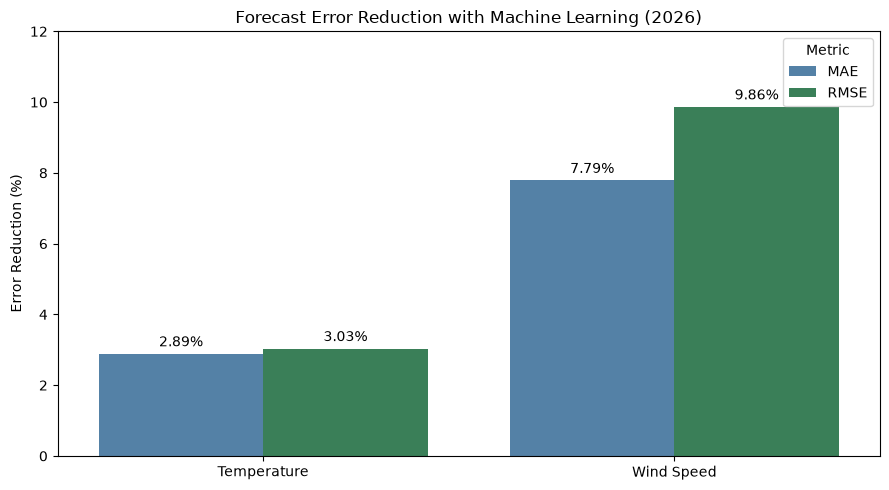

In [24]:
results = []

for feature, actual, icon, ml in [
    ("Temperature", test_final["actual_temperature"],
     test_final["temperature_ICON_EU"], temp_pred_2026),

    ("Wind Speed", test_final["actual_wind_speed"],
     test_final["wind_speed_ICON_EU"], wind_pred_2026)
]:
    for metric, function in [
        ("MAE", mean_absolute_error),
        ("RMSE", root_mean_squared_error)
    ]:
        icon_error = function(actual, icon)
        ml_error = function(actual, ml)

        results.append({
            "Feature": feature,
            "Metric": metric,
            "Improvement (%)": (icon_error - ml_error) / icon_error * 100
        })

improvement_df = pd.DataFrame(results)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=improvement_df,
    x="Feature",
    y="Improvement (%)",
    hue="Metric",
    palette=["steelblue", "seagreen"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Forecast Error Reduction with Machine Learning (2026)")
plt.xlabel("")
plt.ylabel("Error Reduction (%)")
plt.ylim(0, 12)
plt.legend(title="Metric")

plt.tight_layout()
plt.show()

,Feature,ML better,ICON-EU better,Equal
0,Temperature,54.80,45.20,0.0
1,Wind Speed,54.03,45.97,0.0


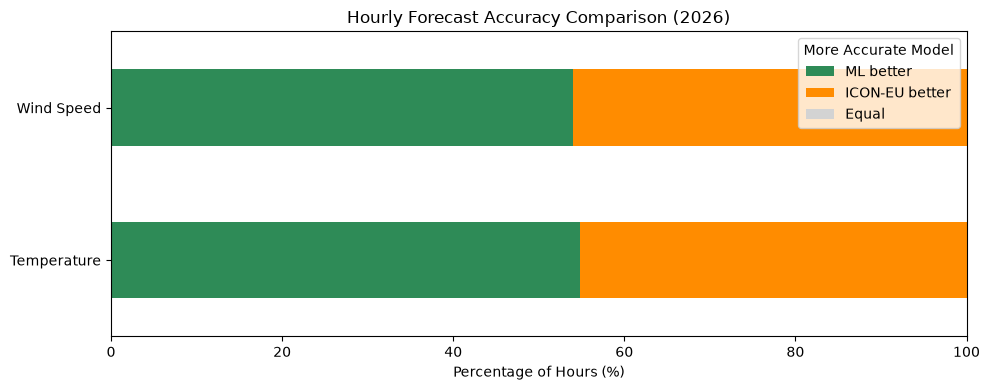

In [25]:
hourly_results = []

for feature, actual, icon, ml in [
    ("Temperature", test_final["actual_temperature"],
     test_final["temperature_ICON_EU"], temp_pred_2026),

    ("Wind Speed", test_final["actual_wind_speed"],
     test_final["wind_speed_ICON_EU"], wind_pred_2026)
]:
    icon_error = np.abs(np.array(actual) - np.array(icon))
    ml_error = np.abs(np.array(actual) - np.array(ml))

    hourly_results.append({
        "Feature": feature,
        "ML better": np.mean(ml_error < icon_error) * 100,
        "ICON-EU better": np.mean(icon_error < ml_error) * 100,
        "Equal": np.mean(icon_error == ml_error) * 100
    })

hourly_df = pd.DataFrame(hourly_results)

display(hourly_df.round(2))

hourly_df.set_index("Feature")[
    ["ML better", "ICON-EU better", "Equal"]
].plot(
    kind="barh",
    stacked=True,
    figsize=(10, 4),
    color=["seagreen", "darkorange", "lightgray"]
)

plt.title("Hourly Forecast Accuracy Comparison (2026)")
plt.xlabel("Percentage of Hours (%)")
plt.ylabel("")
plt.xlim(0, 100)
plt.legend(title="More Accurate Model")

plt.tight_layout()
plt.show()

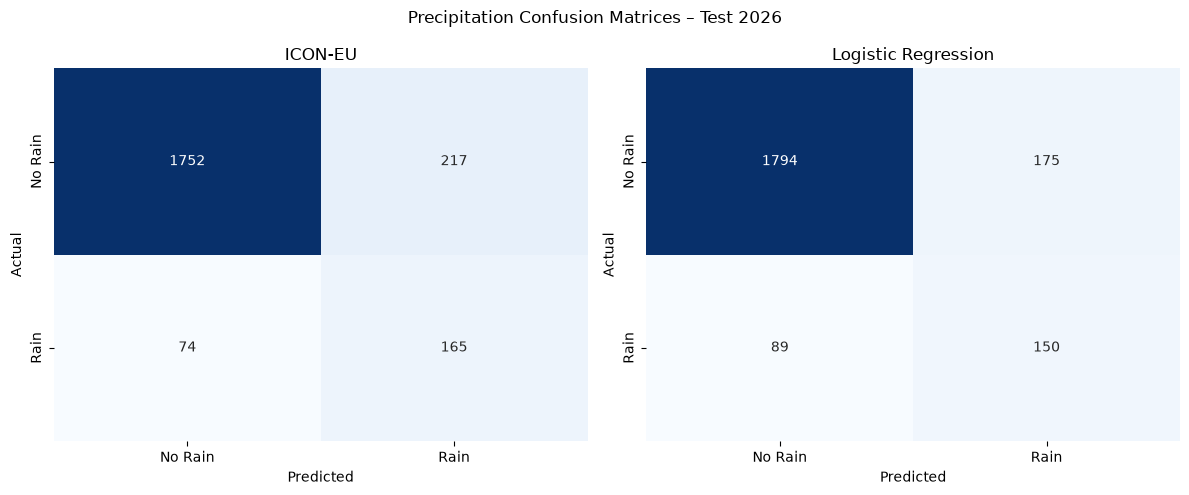

In [26]:
cm_icon = confusion_matrix(
    y_test_rain, icon_rain_2026, labels=[0, 1]
)

cm_lr = confusion_matrix(
    y_test_rain, rain_pred_2026, labels=[0, 1]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, cm, title in zip(
    axes,
    [cm_icon, cm_lr],
    ["ICON-EU", "Logistic Regression"]
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No Rain", "Rain"],
        yticklabels=["No Rain", "Rain"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Precipitation Confusion Matrices – Test 2026")
plt.tight_layout()
plt.show()

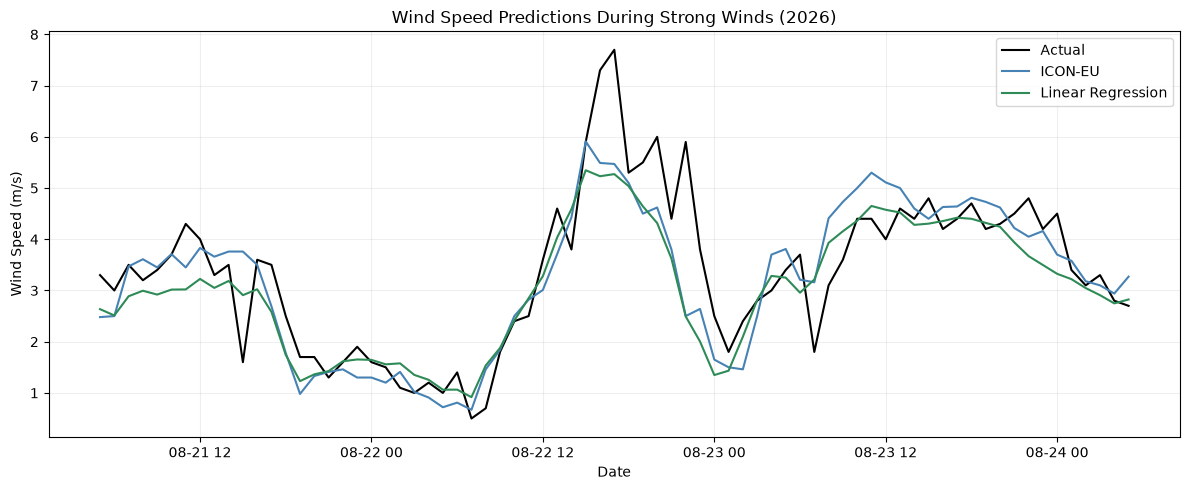

In [27]:
wind_plot = pd.DataFrame({
    "time": test_final["time"].values,
    "Actual": test_final["actual_wind_speed"].values,
    "ICON-EU": test_final["wind_speed_ICON_EU"].values,
    "Linear Regression": wind_pred_2026
})

# Leiame suurima tuulekiirusega tunni
peak_time = wind_plot.loc[
    wind_plot["Actual"].idxmax(), "time"
]

# Võtame 36 tundi enne ja pärast seda
wind_period = wind_plot[
    (wind_plot["time"] >= peak_time - pd.Timedelta(hours=36)) &
    (wind_plot["time"] <= peak_time + pd.Timedelta(hours=36))
]

plt.figure(figsize=(12, 5))

plt.plot(
    wind_period["time"],
    wind_period["Actual"],
    label="Actual",
    color="black"
)

plt.plot(
    wind_period["time"],
    wind_period["ICON-EU"],
    label="ICON-EU",
    color="steelblue"
)

plt.plot(
    wind_period["time"],
    wind_period["Linear Regression"],
    label="Linear Regression",
    color="seagreen"
)

plt.title("Wind Speed Predictions During Strong Winds (2026)")
plt.xlabel("Date")
plt.ylabel("Wind Speed (m/s)")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Final Results and Visualization Analysis**

The results show that combining ECMWF, GFS, and ICON-EU forecasts using machine learning improved temperature and wind speed predictions on the 2026 test dataset.

Linear Regression reduced temperature MAE by 2.89% and wind speed MAE by 7.79%. However, the hourly comparison showed that machine learning predictions were more accurate in only approximately 54–55% of the hours, indicating that ICON-EU still performed better in many individual cases.

The strong wind visualization also revealed that both models underestimated the highest observed wind speeds, highlighting a limitation of the approach.

For precipitation, Logistic Regression reduced the number of false alarms from 217 to 175, but missed more actual rainfall events (89 compared to 74). Consequently, both models achieved nearly identical F1-scores.

Overall, machine learning improved the average accuracy of temperature and wind speed predictions, while the improvement in precipitation prediction was limited. The results also demonstrate that better overall accuracy does not guarantee better predictions for every hour or extreme weather event.